# CASE 4 REPORT 
### Introduction

This report is on the prediction of the price of bitcoin 

In [1]:
# import neccesary libraries
import os 
import pandas as pd
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
#from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import accuracy_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier

### Bitcoin Data Exploration

In [ ]:
# MANUALLY DOWNLOAD GOLD AND BITCOIN DATA FROM YAHOOFINANCE AS IT IS PROVING DIFFICULT TO FETCH DIRECTLY 
# Load bitcoin data
bitcoin_data = pd.read_csv("../data/BTC-USD2.csv")
bitcoin_data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,14/02/2024,49733.44531,51953.66016,49343.67969,51573.92969,51573.92969,3.989712e+10
1,13/02/2024,49941.35938,50358.39063,48406.49609,49742.44141,49742.44141,3.559305e+10
2,12/02/2024,48296.38672,50280.47656,47745.76172,49958.22266,49958.22266,3.451199e+10
3,11/02/2024,47768.96875,48535.93750,47617.40625,48293.91797,48293.91797,1.931587e+10
4,10/02/2024,47153.52734,48146.17188,46905.32031,47771.27734,47771.27734,1.639868e+10


In [ ]:
# Get more information about the data
bitcoin_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3697 entries, 0 to 3696
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       3332 non-null   object 
 1   Open       3332 non-null   float64
 2   High       3332 non-null   float64
 3   Low        3332 non-null   float64
 4   Close      3332 non-null   float64
 5   Adj Close  3332 non-null   float64
 6   Volume     3332 non-null   float64
dtypes: float64(6), object(1)
memory usage: 202.3+ KB


In [ ]:
# sort data by date from later to earlier
bitcoin_data["Date"] = pd.to_datetime(bitcoin_data["Date"], format="%d/%m/%Y")
bitcoin_data = bitcoin_data.sort_values(by = "Date")
bitcoin_data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
3331,2015-01-01,320.434998,320.434998,314.002991,314.248993,314.248993,8036550.0
3330,2015-01-02,314.079010,315.838989,313.565002,315.032013,315.032013,7860650.0
3329,2015-01-03,314.846008,315.149994,281.082001,281.082001,281.082001,33054400.0
3328,2015-01-04,281.145996,287.230011,257.612000,264.195007,264.195007,55629100.0
3327,2015-01-05,265.084015,278.341003,265.084015,274.473999,274.473999,43962800.0


In [ ]:
# Check for the number of null
bitcoin_data.isna().sum()

Date         365
Open         365
High         365
Low          365
Close        365
Adj Close    365
Volume       365
dtype: int64

This shows that their are 365 null values in each of those columns listed

In [ ]:
# Get the summary statistics for the data
bitcoin_data.describe()

,Date,Open,High,Low,Close,Adj Close,Volume
count,3332,3332.000000,3332.000000,3332.000000,3332.000000,3332.000000,3.332000e+03
mean,2019-07-24 12:00:00,15416.339995,15775.534990,15032.748588,15430.377846,15430.377846,1.719896e+10
min,2015-01-01 00:00:00,176.897003,211.731003,171.509995,178.102997,178.102997,7.860650e+06
25%,2017-04-12 18:00:00,1223.099975,1239.935028,1207.577515,1223.280029,1223.280029,4.070770e+08
50%,2019-07-24 12:00:00,8788.635254,8957.514160,8573.421387,8790.644043,8790.644043,1.311849e+10
75%,2021-11-03 06:00:00,26303.238280,26720.072265,25913.203128,26329.301757,26329.301757,2.747484e+10
max,2024-02-14 00:00:00,67549.734380,68789.625000,66382.062500,67566.828130,67566.828130,3.510000e+11
std,NaN,16466.845922,16860.166998,16032.268512,16473.783274,16473.783274,1.908799e+10


### Visualisation and KPIs

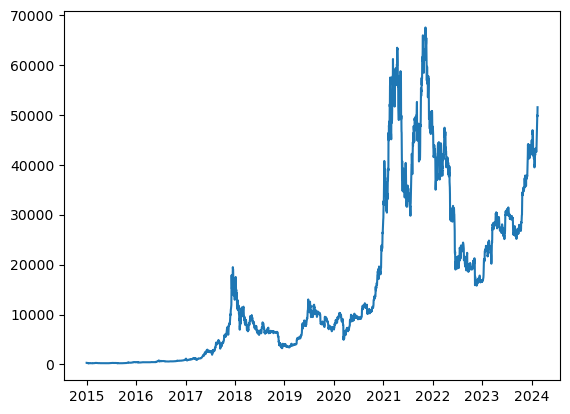

In [ ]:
# plot chart to show price trend
plt.plot(bitcoin_data['Date'], bitcoin_data['Close'])
plt.show()

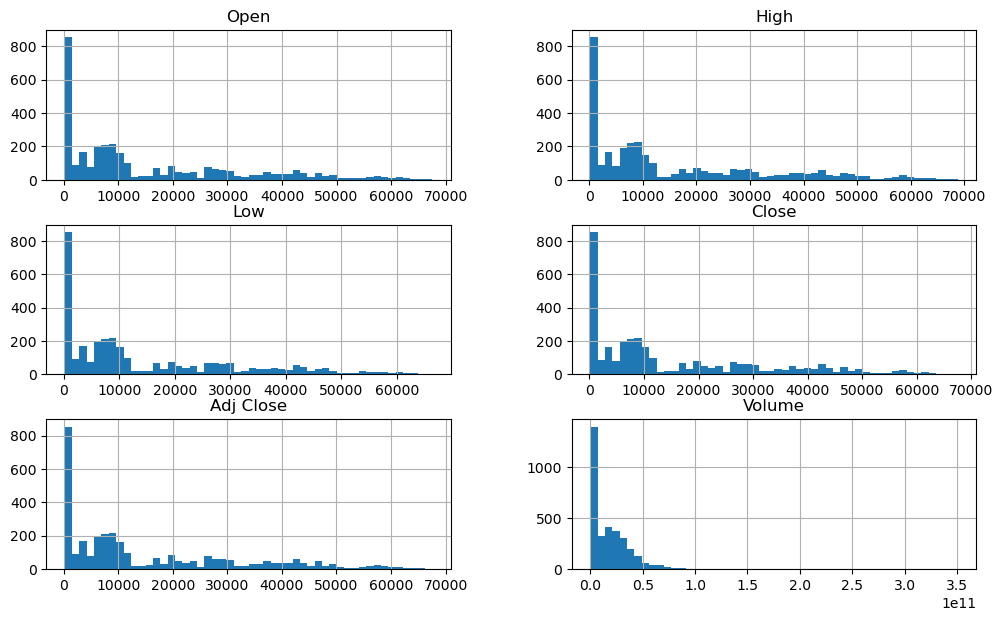

In [ ]:
%matplotlib inline
bitcoin_data_features = bitcoin_data.drop("Date", axis=1)
bitcoin_data_features.hist(bins=50, figsize=(12,7))
plt.show()

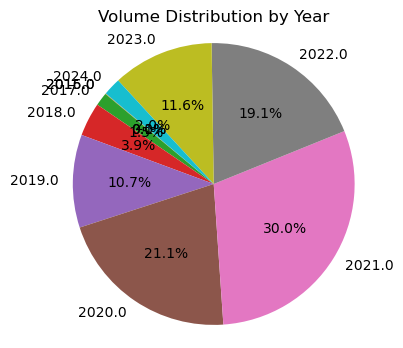

In [ ]:
# Pie Chart showing the Volume distribution by year
bitcoin_data['Date'] = pd.to_datetime(bitcoin_data['Date'], dayfirst=True)
# Extract year from the 'Date' column
bitcoin_data['Year'] = bitcoin_data['Date'].dt.year
# Group by year and sum up the volume
volume_by_year = bitcoin_data.groupby('Year')['Volume'].sum()

plt.figure(figsize=(4, 4))
plt.pie(volume_by_year, labels=volume_by_year.index, autopct='%1.1f%%', startangle=140)
plt.title('Volume Distribution by Year')
plt.axis('equal')  
plt.show()

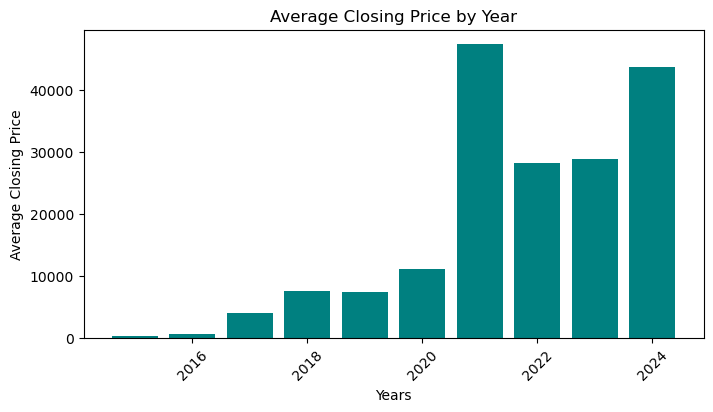

In [ ]:
# Plot a bar chart of the average closing Price of each year under consideration
average_close_by_year = bitcoin_data.groupby('Year')['Close'].mean()
# Extract labels (years) and values (average closing prices)
labels = average_close_by_year.index
values = average_close_by_year.values
plt.figure(figsize=(8, 4))
plt.bar(labels, values, color='teal')
plt.xlabel('Years')
plt.ylabel('Average Closing Price')
plt.title('Average Closing Price by Year')
plt.xticks(rotation=45) 
#plt.tight_layout() 
plt.show()

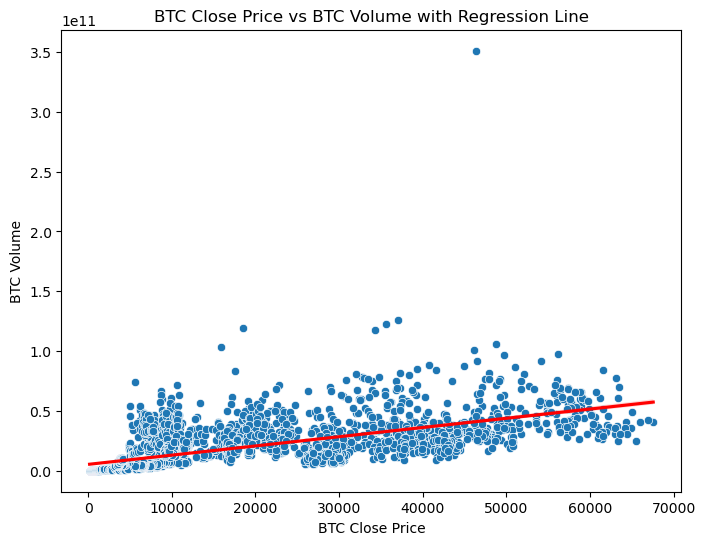

In [ ]:
# Scatter plot of the closing price and the volume with a regression line
plt.figure(figsize=(8, 6))
sns.scatterplot(x=bitcoin_data['Close'], y=bitcoin_data['Volume'])
sns.regplot(x=bitcoin_data['Close'], y=bitcoin_data['Volume'], scatter=False, color='red') 
plt.title('BTC Close Price vs BTC Volume with Regression Line')
plt.xlabel('BTC Close Price')
plt.ylabel('BTC Volume')
plt.show()

### Preparing the Data

In [ ]:
# Drop Null values
BitC_data = bitcoin_data.dropna()
BitC_data.isna().any()

Date         False
Open         False
High         False
Low          False
Close        False
Adj Close    False
Volume       False
Year         False
dtype: bool

#### Feature Engineering 

In [ ]:
# Creating attribute for prediction - NextDay Close.  This is the closing price of the next day
BitC_data = BitC_data.copy()
BitC_data["NextDayClose"] = BitC_data['Close'].shift(-1)
BitC_data.head()

,Date,Open,High,Low,Close,Adj Close,Volume,Year,NextDayClose
3331,2015-01-01,320.434998,320.434998,314.002991,314.248993,314.248993,8036550.0,2015.0,315.032013
3330,2015-01-02,314.079010,315.838989,313.565002,315.032013,315.032013,7860650.0,2015.0,281.082001
3329,2015-01-03,314.846008,315.149994,281.082001,281.082001,281.082001,33054400.0,2015.0,264.195007
3328,2015-01-04,281.145996,287.230011,257.612000,264.195007,264.195007,55629100.0,2015.0,274.473999
3327,2015-01-05,265.084015,278.341003,265.084015,274.473999,274.473999,43962800.0,2015.0,286.188995


In [ ]:
# Create a new column that will store the target value
BitC_data.loc[:, "PriceTrend"] = (BitC_data["NextDayClose"] > BitC_data["Open"]).astype(int)
BitC_data["PriceTrend"].value_counts()

PriceTrend
1    1824
0    1508
Name: count, dtype: int64

In [ ]:
# Computing new features
# Price change
BitC_data.loc[:, "PriceChange"] = BitC_data["Close"] - BitC_data["Open"]

#Trend Indicators (e.g., 50-day and 200-day moving averages)
window_50days = 50
window_200days = 200
BitC_data.loc[:, "50days_MA"] = BitC_data["Close"].rolling(window=window_50days).mean()
BitC_data.loc[:, "200days_MA"] = BitC_data["Close"].rolling(window=window_200days).mean()

# Price Relative to Moving Averages
BitC_data.loc[:, "Price_vs_50days_MA"] = BitC_data["Close"] - BitC_data["50days_MA"]
BitC_data.loc[:, "Price_vs_200days_MA"] = BitC_data["Close"] - BitC_data["200days_MA"]

# Volatility Indicators (e.g., Bollinger Bands)
window_size = 20
BitC_data.loc[:, "RollingStd"] = BitC_data["Close"].rolling(window=window_size).std()
BitC_data.loc[:, "UpperBand"] = BitC_data["50days_MA"] + 2 * BitC_data["RollingStd"]
BitC_data.loc[:,"LowerBand"] = BitC_data["50days_MA"] - 2 * BitC_data["RollingStd"]

BitC_data = BitC_data.dropna()
BitC_data.head()

,Date,Open,High,Low,Close,Adj Close,Volume,Year,NextDayClose,PriceTrend,PriceChange,50days_MA,200days_MA,Price_vs_50days_MA,Price_vs_200days_MA,RollingStd,UpperBand,LowerBand
3132,2015-07-19,274.766998,275.670013,272.513000,273.614014,273.614014,15332500.0,2015.0,278.980988,1,-1.152984,252.227199,247.008470,21.386815,26.605544,14.184152,280.595502,223.858896
3131,2015-07-20,273.498993,278.980988,272.959991,278.980988,278.980988,22711400.0,2015.0,275.833008,1,5.481995,253.203018,246.832130,25.777970,32.148858,13.918339,281.039696,225.366341
3130,2015-07-21,278.881989,280.546997,275.419006,275.833008,275.833008,22930700.0,2015.0,277.221985,0,-3.048981,254.261159,246.636135,21.571849,29.196873,13.313687,280.888533,227.633785
3129,2015-07-22,275.657013,277.665985,274.381012,277.221985,277.221985,19389800.0,2015.0,276.049011,1,1.564972,255.289539,246.616835,21.932446,30.605150,12.331296,279.952130,230.626947
3128,2015-07-23,277.341003,278.110992,275.716003,276.049011,276.049011,18531300.0,2015.0,288.278015,1,-1.291992,256.293039,246.676105,19.755972,29.372906,11.263984,278.821007,233.765071


In [ ]:
# Performing feature scaling with StandardScaler
# Seperate the predictor and target features
ToDrop = ["Date", "PriceTrend"]
predictors = BitC_data.drop(ToDrop, axis=1)
BitC_targ = BitC_data["PriceTrend"]

# Create an instance of the scaler
scaler = StandardScaler()
BitC_pred = pd.DataFrame(scaler.fit_transform(predictors),  columns=predictors.columns)

BitC_pred.head()

,Open,High,Low,Close,Adj Close,Volume,Year,NextDayClose,PriceChange,50days_MA,200days_MA,Price_vs_50days_MA,Price_vs_200days_MA,RollingStd,UpperBand,LowerBand
0,-0.975007,-0.974764,-0.976330,-0.975635,-0.975635,-0.953000,-1.732926,-0.975743,-0.018775,-0.974552,-0.973609,-0.090604,-0.165236,-0.780564,-0.975211,-0.963327
1,-0.975084,-0.974569,-0.976302,-0.975310,-0.975310,-0.952615,-1.732926,-0.975934,-0.010743,-0.974491,-0.973621,-0.089360,-0.164473,-0.780781,-0.975187,-0.963222
2,-0.974757,-0.974476,-0.976149,-0.975500,-0.975500,-0.952604,-1.732926,-0.975850,-0.021070,-0.974426,-0.973634,-0.090551,-0.164879,-0.781274,-0.975195,-0.963065
3,-0.974953,-0.974646,-0.976214,-0.975416,-0.975416,-0.952789,-1.732926,-0.975921,-0.015484,-0.974363,-0.973635,-0.090449,-0.164685,-0.782076,-0.975246,-0.962857
4,-0.974851,-0.974620,-0.976131,-0.975487,-0.975487,-0.952834,-1.732926,-0.975180,-0.018943,-0.974301,-0.973631,-0.091066,-0.164855,-0.782947,-0.975309,-0.962639


##### Feature Importance

In [ ]:
# Split the dataset into train and test sets
BitC_pred_train, BitC_pred_test, BitC_targ_train, BitC_targ_test = train_test_split(
    BitC_pred, BitC_targ, test_size=0.25, random_state=42
)

# Initialize the Random Forest model
rnd_clsf = RandomForestClassifier(n_estimators=100, min_samples_split=50, random_state=1)

# Train the model
rnd_clsf.fit(BitC_pred_train, BitC_targ_train)

# Test the model
targ_predict = rnd_clsf.predict(BitC_pred_test)

# Get feature importances as a Series
importances = pd.Series(rnd_clsf.feature_importances_, index=BitC_pred.columns)

# Sort them from most to least important
importances_sorted = importances.sort_values(ascending=False)

# Display nicely
print(importances_sorted)

PriceChange            0.561011
NextDayClose           0.054174
Price_vs_50days_MA     0.043652
Open                   0.038614
200days_MA             0.034562
LowerBand              0.033348
RollingStd             0.030080
Volume                 0.029901
Price_vs_200days_MA    0.029524
UpperBand              0.026858
50days_MA              0.026647
Low                    0.025254
High                   0.023239
Close                  0.020107
Adj Close              0.017554
Year                   0.005474
dtype: float64


In [ ]:
# Streamlining the dataframe to include just a few features based on the feature importance
selected_features = importances_sorted.head(8).index.tolist()
BitC_train = BitC_pred_train[selected_features]
BitC_test = BitC_pred_test[selected_features]
BitC_train.head()

,PriceChange,NextDayClose,Price_vs_50days_MA,Open,200days_MA,LowerBand,RollingStd,Volume
573,0.001448,-0.932152,-0.079102,-0.931744,-0.941934,-0.921428,-0.745202,-0.948465
3057,1.157756,1.396730,1.071031,1.293318,0.939792,1.311900,-0.152251,0.272845
2848,-0.785156,0.729648,0.003072,0.797822,0.450285,0.892152,-0.139404,-0.123585
1213,-0.033963,-0.645307,-0.129868,-0.605562,-0.530766,-0.537596,-0.743195,-0.718840
2093,0.416888,2.632504,1.408328,2.633853,1.083109,2.507125,1.115931,1.460608


### Building Classification Models


Because our target feature has now been converted to binary, we have a classification problem of predicting the probability that the closing price of the next day is either higher than the opening  price of the current day - class 1 or vice versa, for class 0

##### Logistic Regression

In [ ]:
# Instantiating the model
lg_reg = LogisticRegression()

# perform cross validation on the new train dataset
kf = KFold(n_splits=10, shuffle=True, random_state=1)
cv_scores = cross_val_score(lg_reg, BitC_train, BitC_targ_train, cv=kf, scoring="accuracy")

print("Cross-validation scores:", cv_scores)
print("Mean of CV accuracy:", cv_scores.mean())
print("Standard deviation of CV accuracy:", cv_scores.std())

Cross-validation scores: [0.76170213 0.72340426 0.77021277 0.75319149 0.71914894 0.74893617
 0.75744681 0.71489362 0.77021277 0.77350427]
Mean of CV accuracy: 0.7492653209674487
Standard deviation of CV accuracy: 0.021117426791114023


Precision Score:  0.7087033747779752
Accuracy Score:  0.7484035759897829


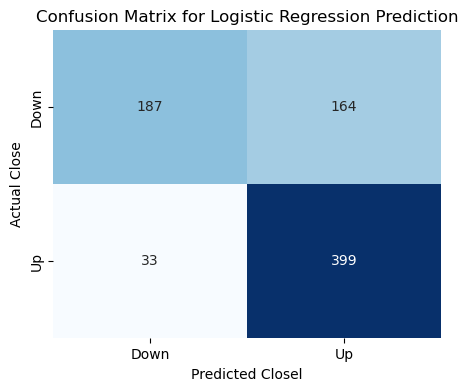

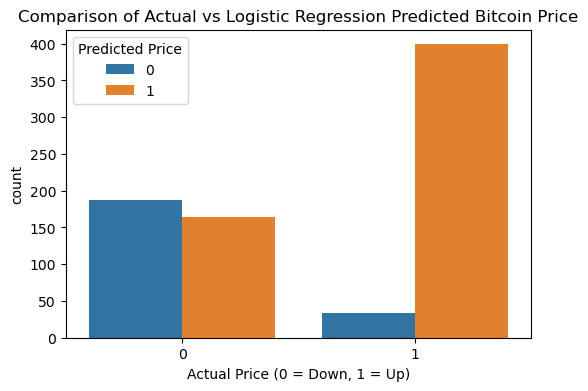

In [ ]:
# Train and test the model
lg_reg.fit(BitC_train, BitC_targ_train)

lg_reg_pred = lg_reg.predict(BitC_test)

# Model Evaluation

# Get precision score
lg_precision = precision_score(BitC_targ_test, lg_reg_pred) 
print("Precision Score: ", lg_precision) 

# Get accuracy score 
lg_accuracy = accuracy_score(BitC_targ_test, lg_reg_pred) 
print("Accuracy Score: ", lg_accuracy)

# Get precision score
#print("Precision Score: ", precision_score(BitC_targ_test, lg_reg_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(BitC_targ_test, lg_reg_pred))

# Compute Confusion Matrix
cm = confusion_matrix(BitC_targ_test, lg_reg_pred)

# Visualising Logistic Regression result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Logistic Regression Prediction")
plt.xlabel("Predicted Closel")
plt.ylabel("Actual Close")
plt.show()

# Visualising Logistic Regression result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": BitC_targ_test,
    "Predicted": lg_reg_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Logistic Regression Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### Random Forest

In [ ]:
# perform cross validation on the new train dataset
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(rnd_clsf, BitC_train, BitC_targ_train, cv=kf, scoring="accuracy")

print("Cross-validation scores:", cv_scores)
print("Mean of CV accuracy:", cv_scores.mean())
print("Standard deviation of CV accuracy:", cv_scores.std())

Cross-validation scores: [0.74893617 0.78297872 0.76595745 0.71914894 0.75319149 0.75744681
 0.77021277 0.75744681 0.76595745 0.71367521]
Mean of CV accuracy: 0.7534951809419894
Standard deviation of CV accuracy: 0.020680364883789187


Precision Score:  0.7706013363028953
Accuracy Score:  0.7586206896551724


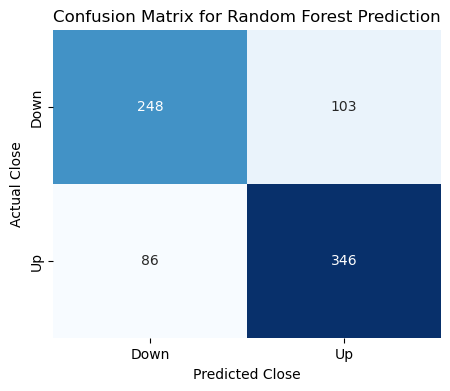

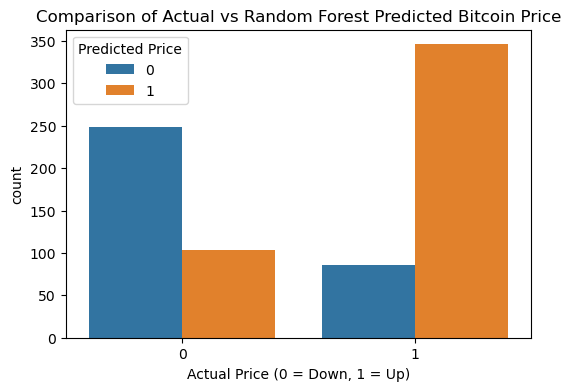

In [ ]:
## Train and test the new dataframe with the already Instantiated Random Forest Classifier

rnd_clsf.fit(BitC_train, BitC_targ_train)
rn_fr_pred = rnd_clsf.predict(BitC_test)

# Model Evaluation

# Get precision score
rn_precision = precision_score(BitC_targ_test, rn_fr_pred) 
print("Precision Score: ", rn_precision) 

# Get accuracy score 
rn_accuracy = accuracy_score(BitC_targ_test, rn_fr_pred) 
print("Accuracy Score: ", rn_accuracy)

# Get precision score
#print("Precision Score: ", precision_score(BitC_targ_test, rn_fr_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(BitC_targ_test, rn_fr_pred))

# Compute confusion matrix
rn_fr_cm = confusion_matrix(BitC_targ_test, rn_fr_pred)

# Visualising Random Forest result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(rn_fr_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Random Forest Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising Random Forest result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": BitC_targ_test,
    "Predicted": rn_fr_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Random Forest Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### Bagging Classifier

In [ ]:
# Instantiating the model
bag_clf = BaggingClassifier(
    RandomForestClassifier(n_estimators=100, min_samples_split=50, random_state=1)
)

# perform cross validation on the train dataset
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(bag_clf, BitC_train, BitC_targ_train, cv=kf, scoring="accuracy")

print("Cross-validation scores:", cv_scores)
print("Mean of CV accuracy:", cv_scores.mean())
print("Standard deviation of CV accuracy:", cv_scores.std())

Cross-validation scores: [0.74042553 0.79148936 0.75319149 0.73191489 0.74042553 0.77021277
 0.77446809 0.76170213 0.77021277 0.72649573]
Mean of CV accuracy: 0.7560538279687216
Standard deviation of CV accuracy: 0.019951606521669125


Precision Score:  0.7725225225225225
Accuracy Score:  0.7573435504469987


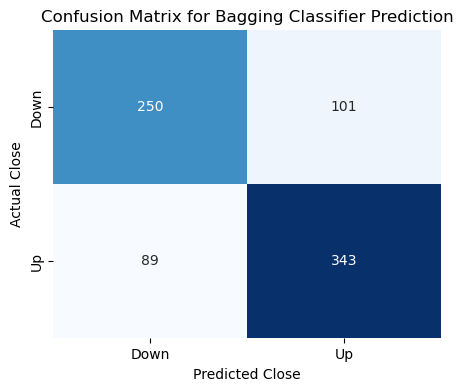

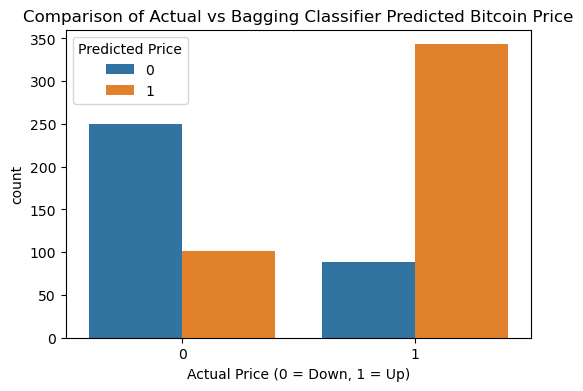

In [ ]:
#Train and test the Bagging Classifier
bag_clf.fit(BitC_train, BitC_targ_train)
bag_pred = bag_clf.predict(BitC_test)

# Model Evaluation
# Get precision score
bg_precision = precision_score(BitC_targ_test, bag_pred) 
print("Precision Score: ", bg_precision) 

# Get accuracy score 
bg_accuracy = accuracy_score(BitC_targ_test, bag_pred) 
print("Accuracy Score: ", bg_accuracy)

# Get precision score
#print("Precision Score: ", precision_score(BitC_targ_test, bag_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(BitC_targ_test, bag_pred))

# Compute confusion matrix
bag_cm = confusion_matrix(BitC_targ_test, bag_pred)

# Visualising Bagging Classifier result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(bag_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Bagging Classifier Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising Bagging Classifier result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": BitC_targ_test,
    "Predicted": bag_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Bagging Classifier Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### GradientBoosting Classifier

In [ ]:
# Instantiating the model
gb_clf = GradientBoostingClassifier(n_estimators=3, learning_rate=0.5, max_depth=1, random_state=0)

# perform cross validation on the train dataset
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(gb_clf, BitC_train, BitC_targ_train, cv=kf, scoring="accuracy")

print("Cross-validation scores:", cv_scores)
print("Mean of CV accuracy:", cv_scores.mean())
print("Standard deviation of CV accuracy:", cv_scores.std())

Cross-validation scores: [0.73191489 0.7787234  0.75744681 0.76170213 0.73617021 0.74042553
 0.76595745 0.75744681 0.76170213 0.73931624]
Mean of CV accuracy: 0.7530805601018367
Standard deviation of CV accuracy: 0.01446966593271585


Precision Score:  0.7725225225225225
Accuracy Score:  0.756066411238825


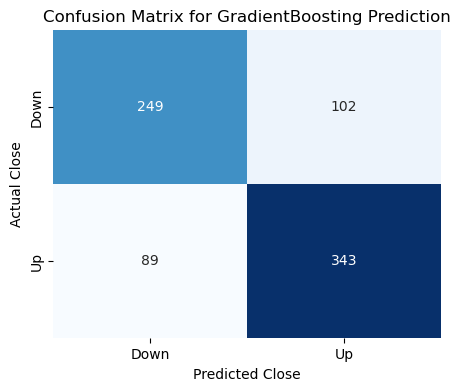

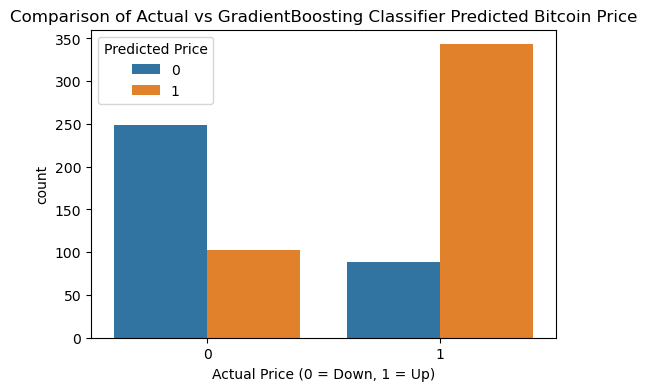

In [ ]:
# Train and test the GradientBoosting Classifier model
gb_clf.fit(BitC_pred_train, BitC_targ_train)
gradboost_pred = gb_clf.predict(BitC_pred_test)

# Model Evaluation
# Get precision score
gb_precision = precision_score(BitC_targ_test, gradboost_pred) 
print("Precision Score: ", bg_precision) 

# Get accuracy score 
gb_accuracy = accuracy_score(BitC_targ_test, gradboost_pred) 
print("Accuracy Score: ", gb_accuracy)

# Get precision score
#print("Precision Score: ", precision_score(BitC_targ_test, gradboost_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(BitC_targ_test, gradboost_pred))

# Compute confusion matrix 
gradboost_cm = confusion_matrix(BitC_targ_test, gradboost_pred)

# Visualising GradientBoosting Classifier result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(gradboost_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for GradientBoosting Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising GradientBoosting Classifier result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": BitC_targ_test,
    "Predicted": gradboost_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs GradientBoosting Classifier Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

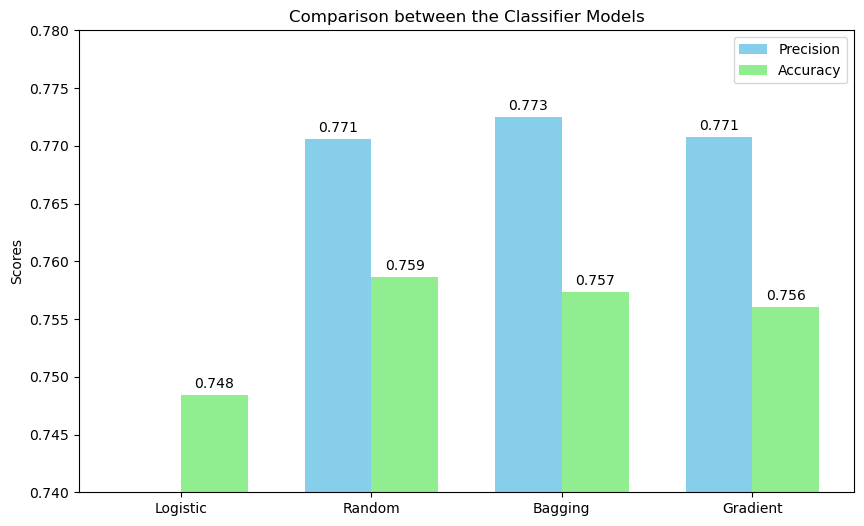

In [ ]:
# Visual comparison between models
# Models
models = ["Logistic", "Random", "Bagging", "Gradient"]

# Precision and Accuracy scores
precision = [lg_precision, rn_precision, bg_precision, gb_precision]
accuracy = [lg_accuracy, rn_accuracy, bg_accuracy, gb_accuracy]

# Set up bar positions
x = np.arange(len(models))
width = 0.35

# Plot
fig, ax = plt.subplots(figsize=(10,6))
rects1 = ax.bar(x - width/2, precision, width, label="Precision", color="skyblue")
rects2 = ax.bar(x + width/2, accuracy, width, label="Accuracy", color="lightgreen")

# Add labels, title, legend
ax.set_ylabel("Scores")
ax.set_title("Comparison between the Classifier Models")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Annotate bars with values
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.ylim(0.74, 0.78)  # zoom in for better comparison
plt.show()

### Gold Data Exploration

In [ ]:
# Load gold data
gold_data = pd.read_csv("GOLD.csv")
gold_data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-01-02,10.54,10.94,10.45,10.91,9.288097,13884500
1,2015-01-05,10.98,11.08,10.52,10.90,9.279585,16028900
2,2015-01-06,11.02,11.46,10.93,11.27,9.594578,21643700
3,2015-01-07,11.08,11.41,10.93,11.12,9.466879,14361600
4,2015-01-08,11.01,11.30,10.75,10.81,9.202964,18134100


In [ ]:
# Get more information about the data
gold_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2295 entries, 0 to 2294
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2295 non-null   object 
 1   Open       2295 non-null   float64
 2   High       2295 non-null   float64
 3   Low        2295 non-null   float64
 4   Close      2295 non-null   float64
 5   Adj Close  2295 non-null   float64
 6   Volume     2295 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 125.6+ KB


In [ ]:
# sort data by date from later to earlier
gold_data["Date"] = pd.to_datetime(gold_data["Date"], format="%Y-%m-%d")
gold_data = gold_data.sort_values(by = "Date")
gold_data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-01-02,10.54,10.94,10.45,10.91,9.288097,13884500
1,2015-01-05,10.98,11.08,10.52,10.90,9.279585,16028900
2,2015-01-06,11.02,11.46,10.93,11.27,9.594578,21643700
3,2015-01-07,11.08,11.41,10.93,11.12,9.466879,14361600
4,2015-01-08,11.01,11.30,10.75,10.81,9.202964,18134100


In [ ]:
# Set the date column as index for both the bitcoin data and the gold data 
BitC_data.set_index("Date", inplace=True)
gold_data.set_index("Date", inplace=True)

# Rename the gold close column while joinin it to the bitcoin dataset
bitcoin_with_gold = BitC_data.join(gold_data[["Adj Close"]].rename(columns={"Adj Close": "Gold_Close"}), how="left")
bitcoin_with_gold.head()

,Open,High,Low,Close,Adj Close,Volume,Year,NextDayClose,PriceTrend,PriceChange,50days_MA,200days_MA,Price_vs_50days_MA,Price_vs_200days_MA,RollingStd,UpperBand,LowerBand,Gold_Close
Date,,,,,,,,,,,,,,,,,,
2015-07-19,274.766998,275.670013,272.513000,273.614014,273.614014,15332500.0,2015.0,278.980988,1,-1.152984,252.227199,247.008470,21.386815,26.605544,14.184152,280.595502,223.858896,NaN
2015-07-20,273.498993,278.980988,272.959991,278.980988,278.980988,22711400.0,2015.0,275.833008,1,5.481995,253.203018,246.832130,25.777970,32.148858,13.918339,281.039696,225.366341,6.360746
2015-07-21,278.881989,280.546997,275.419006,275.833008,275.833008,22930700.0,2015.0,277.221985,0,-3.048981,254.261159,246.636135,21.571849,29.196873,13.313687,280.888533,227.633785,6.438002
2015-07-22,275.657013,277.665985,274.381012,277.221985,277.221985,19389800.0,2015.0,276.049011,1,1.564972,255.289539,246.616835,21.932446,30.605150,12.331296,279.952130,230.626947,6.317827
2015-07-23,277.341003,278.110992,275.716003,276.049011,276.049011,18531300.0,2015.0,288.278015,1,-1.291992,256.293039,246.676105,19.755972,29.372906,11.263984,278.821007,233.765071,6.068892


In [ ]:
# check for the presence of null in the joined dataset
bitcoin_with_gold.isna().sum()

Open                     0
High                     0
Low                      0
Close                    0
Adj Close                0
Volume                   0
Year                     0
NextDayClose             0
PriceTrend               0
PriceChange              0
50days_MA                0
200days_MA               0
Price_vs_50days_MA       0
Price_vs_200days_MA      0
RollingStd               0
UpperBand                0
LowerBand                0
Gold_Close             974
dtype: int64

In [ ]:

# These gaps are mostly due to weekends and market holidays when gold do not trade unlike bitcoin that trades everyday. 
# Confirm what days are missing
# first change the date index back to column
bitcoin_with_gold.reset_index(inplace=True)
missing_dates = bitcoin_with_gold.loc[bitcoin_with_gold["Gold_Close"].isna(), "Date"]
print("first_few_missing_dates:\n", missing_dates.head(10))
print("Total missing:", missing_dates.shape[0])

first_few_missing_dates:
 0    2015-07-19
6    2015-07-25
7    2015-07-26
13   2015-08-01
14   2015-08-02
20   2015-08-08
21   2015-08-09
27   2015-08-15
28   2015-08-16
34   2015-08-22
Name: Date, dtype: datetime64[ns]
Total missing: 974


In [ ]:
# Hence we assume that gold price stays the same over non-trading days
# Use forward fill to fill in missing days for gold close
bitcoin_with_gold.loc[:, "Gold_Close"] = bitcoin_with_gold["Gold_Close"].ffill()
# Back fill missing values at the start (first row(s)), if there is/are
bitcoin_with_gold.loc[:, "Gold_Close"] = bitcoin_with_gold["Gold_Close"].bfill()

# check if there are still null values in the Gold_Close column of the merged dataset
bitcoin_with_gold["Gold_Close"].isna().sum()

0

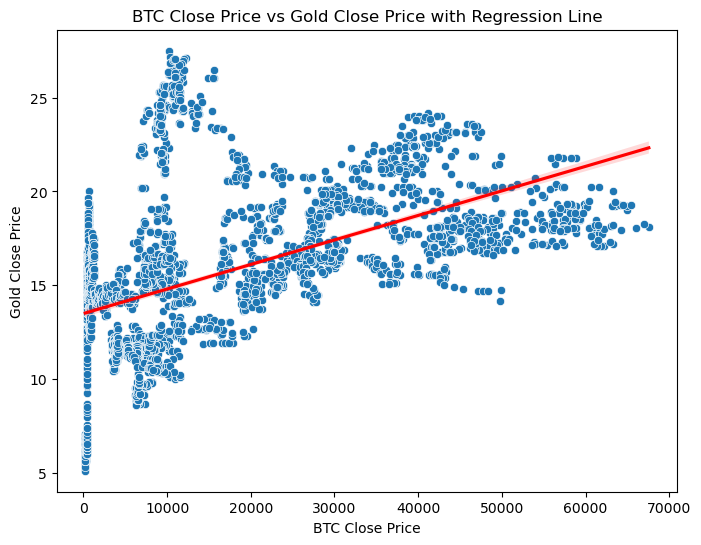

In [ ]:
# Scatter plot of the closing price and the volume with a regression line
plt.figure(figsize=(8, 6))
sns.scatterplot(x=bitcoin_with_gold["Close"], y=bitcoin_with_gold["Gold_Close"])
sns.regplot(x=bitcoin_with_gold["Close"], y=bitcoin_with_gold["Gold_Close"], scatter=False, color="red") 
plt.title("BTC Close Price vs Gold Close Price with Regression Line")
plt.xlabel("BTC Close Price")
plt.ylabel("Gold Close Price")
plt.show()

In [ ]:
# Create a new dataframe consisting the earlier selected features and the close price of Gold  and seperating the predictors from the target
selected_features.append("Gold_Close")
bitc_with_gold_features = bitcoin_with_gold[selected_features]
bitc_with_gold_target = bitcoin_with_gold["PriceTrend"]

bitc_with_gold_features, bitc_with_gold_target

(      PriceChange  NextDayClose  Price_vs_50days_MA          Open  \
 0       -1.152984    278.980988           21.386815    274.766998   
 1        5.481995    275.833008           25.777970    273.498993   
 2       -3.048981    277.221985           21.571849    278.881989   
 3        1.564972    276.049011           21.932446    275.657013   
 4       -1.291992    288.278015           19.755972    277.341003   
 ...           ...           ...                 ...           ...   
 3127  1849.816410  47771.277340         4060.497501  45297.382810   
 3128   617.750000  48293.917970         4609.108121  47153.527340   
 3129   524.949220  49958.222660         5040.661251  47768.968750   
 3130  1661.835940  49742.441410         6566.123831  48296.386720   
 3131  -198.917970  51573.929690         6227.756566  49941.359380   
 
         200days_MA     LowerBand   RollingStd        Volume  Gold_Close  
 0       247.008470    223.858896    14.184152  1.533250e+07    6.360746  
 1      

In [ ]:
# Performing feature scaling with StandardScaler
# Create an instance of the scaler
scaler = StandardScaler()
bitc_gold_scaled = pd.DataFrame(scaler.fit_transform(bitc_with_gold_features),  columns=bitc_with_gold_features.columns)

bitc_gold_scaled.head()

,PriceChange,NextDayClose,Price_vs_50days_MA,Open,200days_MA,LowerBand,RollingStd,Volume,Gold_Close
0,-0.018775,-0.975743,-0.090604,-0.975007,-0.973609,-0.963327,-0.780564,-0.953000,-2.072597
1,-0.010743,-0.975934,-0.089360,-0.975084,-0.973621,-0.963222,-0.780781,-0.952615,-2.072597
2,-0.021070,-0.975850,-0.090551,-0.974757,-0.973634,-0.963065,-0.781274,-0.952604,-2.055331
3,-0.015484,-0.975921,-0.090449,-0.974953,-0.973635,-0.962857,-0.782076,-0.952789,-2.082189
4,-0.018943,-0.975180,-0.091066,-0.974851,-0.973631,-0.962639,-0.782947,-0.952834,-2.137822


In [ ]:
##### Build the Bagging Classifier for Gold dataset

In [ ]:
#splitting the dataset into testing and training set
bitc_gold_X_train, bitc_gold_X_test, bitc_gold_y_train, bitc_gold_y_test = train_test_split(bitc_gold_scaled, bitc_with_gold_target, test_size=0.25, random_state=42)

# perform cross validation on the new train dataset
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(rnd_clsf, bitc_gold_X_train, bitc_gold_y_train, cv=kf, scoring="accuracy")

print("Cross-validation scores:", cv_scores)
print("Mean of CV accuracy:", cv_scores.mean())
print("Standard deviation of CV accuracy:", cv_scores.std())

Cross-validation scores: [0.75319149 0.77446809 0.7787234  0.73191489 0.75744681 0.74468085
 0.78297872 0.77446809 0.75744681 0.71367521]
Mean of CV accuracy: 0.7568994362611383
Standard deviation of CV accuracy: 0.02104740449054098


Precision Score:  0.7725225225225225
Accuracy Score:  0.7573435504469987


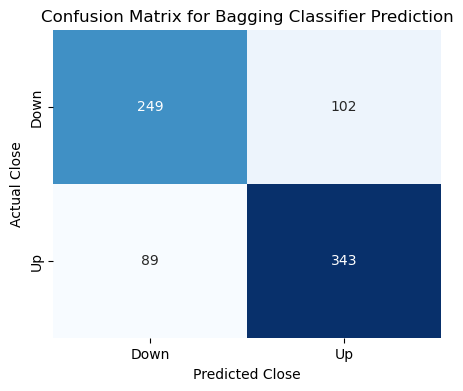

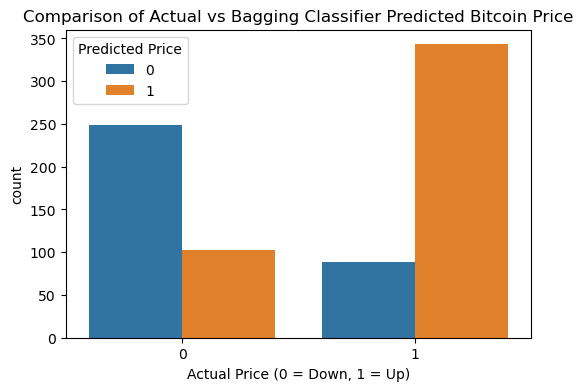

In [ ]:
#Train and test the Bagging Classifier
bag_clf.fit(bitc_gold_X_train, bitc_gold_y_train)
bag_pred = bag_clf.predict(bitc_gold_X_test)

# Model Evaluation
# Get precision score
bg_precision_gold = precision_score(bitc_gold_y_test, bag_pred) 
print("Precision Score: ", bg_precision) 

# Get accuracy score 
bg_accuracy_gold = accuracy_score(bitc_gold_y_test, bag_pred) 
print("Accuracy Score: ", bg_accuracy)

# Get precision score
#print("Precision Score: ", precision_score(BitC_targ_test, bag_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(BitC_targ_test, bag_pred))

# Compute confusion matrix
bag_cm = confusion_matrix(bitc_gold_y_test, bag_pred)

# Visualising Bagging Classifier result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(bag_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Bagging Classifier Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising Bagging Classifier result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": bitc_gold_y_test,
    "Predicted": bag_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Bagging Classifier Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### Build the Random Forest Classifier for Gold dataset

Precision Score:  0.767337807606264
Accuracy Score:  0.7535121328224776


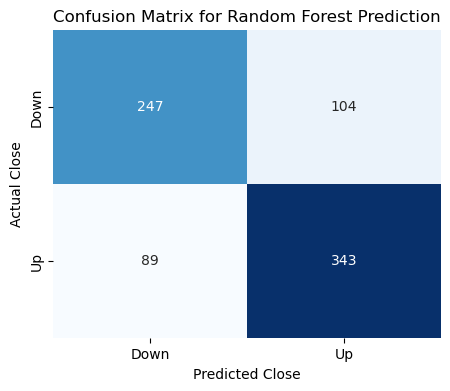

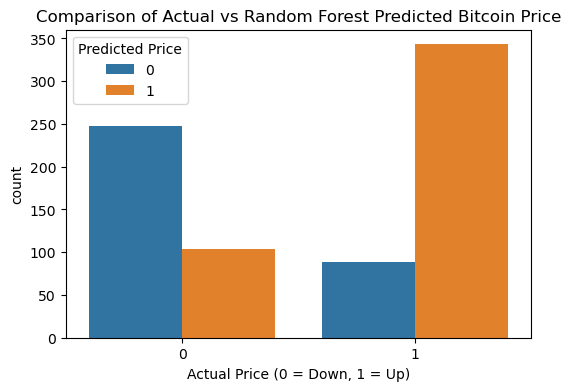

In [ ]:
## Train and test the new dataframe with the already Instantiated Random Forest Classifier

rnd_clsf.fit(bitc_gold_X_train, bitc_gold_y_train)
rn_fr_pred = rnd_clsf.predict(bitc_gold_X_test)

# Model Evaluation
rn_precision_gold = precision_score(bitc_gold_y_test, rn_fr_pred) 
print("Precision Score: ", rn_precision_gold) 

# Get accuracy score 
rn_accuracy_gold = accuracy_score(bitc_gold_y_test, rn_fr_pred) 
print("Accuracy Score: ", rn_accuracy_gold)

# Compute confusion matrix
rn_fr_cm = confusion_matrix(bitc_gold_y_test, rn_fr_pred)

# Visualising Random Forest result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(rn_fr_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Random Forest Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising Random Forest result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": bitc_gold_y_test,
    "Predicted": rn_fr_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Random Forest Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### Build the Gradient Boosting Classifier for Dataset with Gold

Precision Score:  0.7707865168539326
Accuracy Score:  0.756066411238825


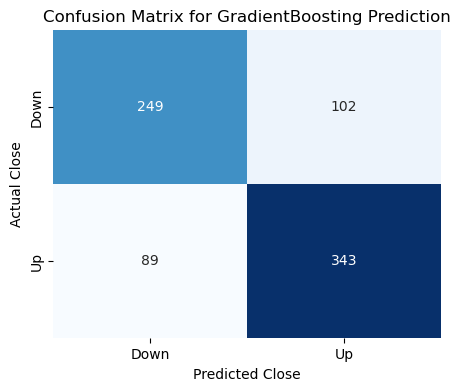

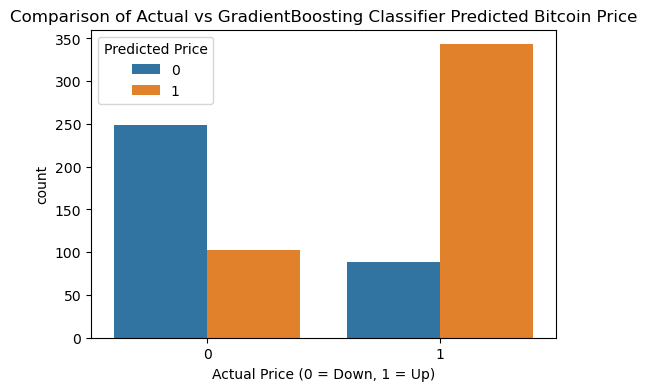

In [ ]:
# Train and test the model
gb_clf.fit(bitc_gold_X_train, bitc_gold_y_train)
gb_y_pred = gb_clf.predict(bitc_gold_X_test)

# Model Evaluation
# Get precision score 
gb_precision_gold = precision_score(bitc_gold_y_test, gb_y_pred) 
print("Precision Score: ", gb_precision_gold) 
# Get accuracy score 
gb_accuracy_gold = accuracy_score(bitc_gold_y_test, gb_y_pred) 
print("Accuracy Score: ", gb_accuracy_gold)

# Get precision score
#print("Precision Score: ", precision_score(bitc_gold_y_test, gb_y_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(bitc_gold_y_test, gb_y_pred))

# Get confusion matrix
gb_cm = confusion_matrix(bitc_gold_y_test, gb_y_pred)

# Visualising GradientBoosting Classifier result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(gb_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for GradientBoosting Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising GradientBoosting Classifier result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": bitc_gold_y_test,
    "Predicted": gb_y_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs GradientBoosting Classifier Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

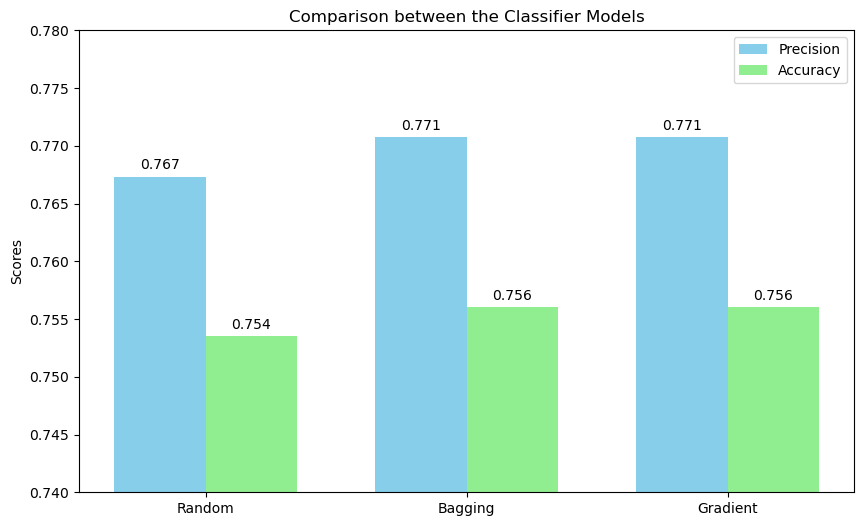

In [ ]:
# Visual conparison between models
models = ["Random", "Bagging", "Gradient"]

# Precision and Accuracy scores
precision = [rn_precision_gold, bg_precision_gold, gb_precision_gold]
accuracy = [rn_accuracy_gold, bg_accuracy_gold, gb_accuracy_gold]

# Set up bar positions
x = np.arange(len(models))
width = 0.35

# Plot
fig, ax = plt.subplots(figsize=(10,6))
rects1 = ax.bar(x - width/2, precision, width, label="Precision", color="skyblue")
rects2 = ax.bar(x + width/2, accuracy, width, label="Accuracy", color="lightgreen")

# Add labels, title, legend
ax.set_ylabel("Scores")
ax.set_title("Comparison between the Classifier Models")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Annotate bars with values
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.ylim(0.74, 0.78)  # zoom in for better comparison
plt.show()

### Checking the effect of ETH and S&P 500 with Bitcoin

In [ ]:
# Load ETH and S&P data
eth_data = pd.read_csv("ETH-USD.csv")
snp_data = pd.read_csv("S&P-500.csv")
# View first few rows of data
#eth_data.head()
eth_data.isna().sum()

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64

In [ ]:
# sort data by date from later to earlier
eth_data["Date"] = pd.to_datetime(eth_data["Date"], format="%m/%d/%Y")
eth_data = eth_data.sort_values(by = "Date")
eth_data.head()

,Date,Open,High,Low,Close
3075,2015-08-07,3,3,3,3
3074,2015-08-08,3,3,0.15,1.2
3073,2015-08-11,0.8,1.15,0.65,0.99
3072,2015-08-12,1,1.29,0.91,1.29
3071,2015-08-13,1.26,1.88,1.26,1.88


In [ ]:
# Check the data type of ETH dataset
snp_data.dtypes

Date         object
Price        object
Open         object
High         object
Low          object
Vol.        float64
Change %     object
dtype: object

In [ ]:
# Clean numeric-looking columns in S&P dataset by removing commas and converting to numbers
def safe_to_numeric(col):
    try:
        return pd.to_numeric(col.astype(str).str.replace(",", ""))
    except Exception:
        return col

eth_data = eth_data.apply(safe_to_numeric)

In [ ]:
#snp_data.head()
snp_data.isna().sum()

Date           0
Price          0
Open           0
High           0
Low            0
Vol.        2295
Change %       0
dtype: int64

In [ ]:
# sort data by date from later to earlier
snp_data["Date"] = pd.to_datetime(snp_data["Date"], format="%d/%m/%Y")
snp_data = snp_data.sort_values(by = "Date")
snp_data.head()

,Date,Price,Open,High,Low,Vol.,Change %
2294,2015-01-02,"2,058.20","2,058.90","2,072.40","2,046.00",NaN,-0.03%
2293,2015-01-05,"2,020.60","2,054.40","2,054.40","2,017.30",NaN,-1.83%
2292,2015-01-06,"2,002.60","2,022.20","2,030.20","1,992.40",NaN,-0.89%
2291,2015-01-07,"2,025.90","2,005.50","2,029.60","2,005.50",NaN,1.16%
2290,2015-01-08,"2,062.10","2,030.60","2,064.10","2,030.60",NaN,1.79%


In [ ]:
# Check the data type of S&P dataset
snp_data.dtypes

Date        datetime64[ns]
Price               object
Open                object
High                object
Low                 object
Vol.               float64
Change %            object
dtype: object

In [ ]:
snp_data = snp_data.apply(safe_to_numeric)
snp_data.head()

,Date,Price,Open,High,Low,Vol.,Change %
2294,2015-01-02,2058.2,2058.9,2072.4,2046.0,NaN,-0.03%
2293,2015-01-05,2020.6,2054.4,2054.4,2017.3,NaN,-1.83%
2292,2015-01-06,2002.6,2022.2,2030.2,1992.4,NaN,-0.89%
2291,2015-01-07,2025.9,2005.5,2029.6,2005.5,NaN,1.16%
2290,2015-01-08,2062.1,2030.6,2064.1,2030.6,NaN,1.79%


In [ ]:

# merge the close column of ETH and S&P with the Bitcoin data

# First we convert the date column to index for the two datasets (Etherium and S&P) to ensure they align when joining them
eth_data.set_index("Date", inplace=True)
snp_data.set_index("Date", inplace=True)
#BitC_data.set_index("Date", inplace=True) #uncomment if the date as not being set as index to set it as index

# Rename the close columns of ETH and S&P while joining them to the bitcoin data
bitcoin_with_eth_snp = BitC_data.join([eth_data[["Close"]].rename(columns={"Close": "ETH_Close"}), snp_data[["Price"]].rename(columns={"Price": "S&P_Close"})], how="left")
bitcoin_with_eth_snp.head()

,Open,High,Low,Close,Adj Close,Volume,Year,NextDayClose,PriceTrend,PriceChange,50days_MA,200days_MA,Price_vs_50days_MA,Price_vs_200days_MA,RollingStd,UpperBand,LowerBand,ETH_Close,S&P_Close
Date,,,,,,,,,,,,,,,,,,,
2015-07-19,274.766998,275.670013,272.513000,273.614014,273.614014,15332500.0,2015.0,278.980988,1.0,-1.152984,252.227199,247.008470,21.386815,26.605544,14.184152,280.595502,223.858896,NaN,NaN
2015-07-20,273.498993,278.980988,272.959991,278.980988,278.980988,22711400.0,2015.0,275.833008,1.0,5.481995,253.203018,246.832130,25.777970,32.148858,13.918339,281.039696,225.366341,NaN,2128.3
2015-07-21,278.881989,280.546997,275.419006,275.833008,275.833008,22930700.0,2015.0,277.221985,0.0,-3.048981,254.261159,246.636135,21.571849,29.196873,13.313687,280.888533,227.633785,NaN,2119.2
2015-07-22,275.657013,277.665985,274.381012,277.221985,277.221985,19389800.0,2015.0,276.049011,1.0,1.564972,255.289539,246.616835,21.932446,30.605150,12.331296,279.952130,230.626947,NaN,2114.2
2015-07-23,277.341003,278.110992,275.716003,276.049011,276.049011,18531300.0,2015.0,288.278015,1.0,-1.291992,256.293039,246.676105,19.755972,29.372906,11.263984,278.821007,233.765071,NaN,2102.2


In [ ]:
bitcoin_with_eth_snp.isna().sum()

Open                     0
High                     0
Low                      0
Close                    0
Adj Close                0
Volume                   0
Year                     0
NextDayClose             0
PriceTrend               0
PriceChange              0
50days_MA                0
200days_MA               0
Price_vs_50days_MA       0
Price_vs_200days_MA      0
RollingStd               0
UpperBand                0
LowerBand                0
ETH_Close               56
S&P_Close              974
dtype: int64

In [ ]:
# Ethereum's trading history only starts around mid-2015 hence the long stretch of NaN values after joining it to the Bitcoin data. 
# To handle this correctly, we trim the Bitcoin dataset to match ETH's available period

# Find ETH's earliest available date
eth_start = eth_data.index.min()

# Filter Bitcoin data to start from that date
BitC_data = BitC_data.loc[BitC_data.index >= eth_start]

# Redo the joining of ETH close and S&P close to the trimmed Bitcoin data
# Rename the close columns of ETH and S&P while joining them to the bitcoin data
bitcoin_with_eth_snp = BitC_data.join([eth_data[["Close"]].rename(columns={"Close": "ETH_Close"}), snp_data[["Price"]].rename(columns={"Price": "S&P_Close"})], how="left")
bitcoin_with_eth_snp.head()

,Open,High,Low,Close,Adj Close,Volume,Year,NextDayClose,PriceTrend,PriceChange,50days_MA,200days_MA,Price_vs_50days_MA,Price_vs_200days_MA,RollingStd,UpperBand,LowerBand,ETH_Close,S&P_Close
Date,,,,,,,,,,,,,,,,,,,
2015-08-07,278.740997,280.391998,276.365997,279.584991,279.584991,42484800.0,2015.0,260.997009,0.0,0.843994,272.185458,249.711125,7.399533,29.873866,6.235271,284.656001,259.714916,3.00,2077.6
2015-08-08,279.742004,279.928009,260.709991,260.997009,260.997009,58533000.0,2015.0,265.083008,0.0,-18.744995,272.513279,249.959535,-11.516270,11.037474,7.752780,288.018839,257.007718,1.20,NaN
2015-08-09,261.115997,267.002991,260.467987,265.083008,265.083008,23789600.0,2015.0,264.470001,1.0,3.967011,272.910699,250.150465,-7.827691,14.932543,8.695021,290.300740,255.520657,NaN,NaN
2015-08-10,265.477997,267.032013,262.596008,264.470001,264.470001,20979400.0,2015.0,270.385986,1.0,-1.007996,273.321219,250.305785,-8.851218,14.164216,9.474613,292.270445,254.371992,NaN,2104.2
2015-08-11,264.342010,270.385986,264.093994,270.385986,270.385986,25433900.0,2015.0,266.376007,1.0,6.043976,273.789138,250.493320,-3.403152,19.892666,9.763928,293.316994,254.261283,0.99,2084.1


In [ ]:

# Check for the presence of missing value in the dataset now
bitcoin_with_eth_snp.isna().sum()

Open                     0
High                     0
Low                      0
Close                    0
Adj Close                0
Volume                   0
Year                     0
NextDayClose             0
PriceTrend               0
PriceChange              0
50days_MA                0
200days_MA               0
Price_vs_50days_MA       0
Price_vs_200days_MA      0
RollingStd               0
UpperBand                0
LowerBand                0
ETH_Close               37
S&P_Close              969
dtype: int64

In [ ]:

#Just as seen in Gold, # these null values are mostly due to weekends and market holidays when gold do not trade unlike bitcoin that trades everyday. 
# Confirm what days are missing
# first change the date index back to column
bitcoin_with_eth_snp.reset_index(inplace=True)
missing_snp_dates = bitcoin_with_eth_snp.loc[bitcoin_with_eth_snp["S&P_Close"].isna(), "Date"]
print("first_few_missing_dates:\n", missing_snp_dates.head(10))
print("Total missing:", missing_snp_dates.shape[0])

first_few_missing_dates:
 1    2015-08-08
2    2015-08-09
8    2015-08-15
9    2015-08-16
15   2015-08-22
16   2015-08-23
22   2015-08-29
23   2015-08-30
29   2015-09-05
30   2015-09-06
Name: Date, dtype: datetime64[ns]
Total missing: 969


In [ ]:
# Hence we assume that S&P price stays the same over non-trading days
# Use forward fill to fill in missing days for S&P close
bitcoin_with_eth_snp.loc[:, "S&P_Close"] = bitcoin_with_eth_snp["S&P_Close"].ffill()
# Back fill missing values at the start (first row(s)), if there is/are any
bitcoin_with_eth_snp.loc[:, "S&P_Close"] = bitcoin_with_eth_snp["S&P_Close"].bfill()

# Use forward fill to fill in the remaining missing days for ETH close 
bitcoin_with_eth_snp.loc[:, "ETH_Close"] = bitcoin_with_eth_snp["ETH_Close"].ffill()
# Back fill missing values at the start (first row(s)), if there is/are any
bitcoin_with_eth_snp.loc[:, "ETH_Close"] = bitcoin_with_eth_snp["ETH_Close"].bfill()

# check if there are still null values in the dataset
bitcoin_with_eth_snp.isna().sum()

Date                   0
Open                   0
High                   0
Low                    0
Close                  0
Adj Close              0
Volume                 0
Year                   0
NextDayClose           0
PriceTrend             0
PriceChange            0
50days_MA              0
200days_MA             0
Price_vs_50days_MA     0
Price_vs_200days_MA    0
RollingStd             0
UpperBand              0
LowerBand              0
ETH_Close              0
S&P_Close              0
dtype: int64

In [ ]:
# Remove the earlier Gold_Close column added from the list of selected features
if "Gold_Close" in selected_features:
    selected_features.remove("Gold_Close")

# Update the selected features list with ETH_Close and S&P_Close columns
selected_features.extend(["ETH_Close", "S&P_Close"])

# Create a new dataframe consisting of the updated selected features
bitc_with_eth_snp_features = bitcoin_with_eth_snp[selected_features]
bitc_with_eth_snp_target = bitcoin_with_eth_snp["PriceTrend"]

bitc_with_eth_snp_features, bitc_with_eth_snp_target

(      PriceChange  NextDayClose  Price_vs_50days_MA          Open  \
 0        0.843994    260.997009            7.399533    278.740997   
 1      -18.744995    265.083008          -11.516270    279.742004   
 2        3.967011    264.470001           -7.827691    261.115997   
 3       -1.007996    270.385986           -8.851218    265.477997   
 4        6.043976    266.376007           -3.403152    264.342010   
 ...           ...           ...                 ...           ...   
 3108  1849.816410  47771.277340         4060.497501  45297.382810   
 3109   617.750000  48293.917970         4609.108121  47153.527340   
 3110   524.949220  49958.222660         5040.661251  47768.968750   
 3111  1661.835940  49742.441410         6566.123831  48296.386720   
 3112  -198.917970  51573.929690         6227.756566  49941.359380   
 
         200days_MA     LowerBand   RollingStd        Volume  ETH_Close  \
 0       249.711125    259.714916     6.235271  4.248480e+07       3.00   
 1      

In [ ]:

# Performing feature scaling with StandardScaler
# Create an instance of the scaler
scaler = StandardScaler()
bitc_eth_snp_scaled = pd.DataFrame(scaler.fit_transform(bitc_with_eth_snp_features),  columns=bitc_with_eth_snp_features.columns)

bitc_eth_snp_scaled.head()

,PriceChange,NextDayClose,Price_vs_50days_MA,Open,200days_MA,LowerBand,RollingStd,Volume,ETH_Close,S&P_Close
0,-0.016411,-0.982657,-0.094834,-0.980580,-0.979237,-0.966506,-0.790918,-0.957145,-0.858702,-1.314195
1,-0.040052,-0.982410,-0.100177,-0.980520,-0.979220,-0.966694,-0.789681,-0.956308,-0.860344,-1.314195
2,-0.012642,-0.982447,-0.099135,-0.981648,-0.979208,-0.966797,-0.788913,-0.958120,-0.860344,-1.314195
3,-0.018646,-0.982089,-0.099425,-0.981384,-0.979198,-0.966877,-0.788277,-0.958266,-0.860344,-1.283675
4,-0.010135,-0.982332,-0.097886,-0.981452,-0.979185,-0.966885,-0.788041,-0.958034,-0.860536,-1.306737


In [ ]:
#splitting the dataset into testing and training set
bitc_eth_snp_X_train, bitc_eth_snp_X_test, bitc_eth_snp_y_train, bitc_eth_snp_y_test = train_test_split(bitc_eth_snp_scaled, bitc_with_eth_snp_target, test_size=0.25, random_state=42)

# Use the already instantiated Gradient Boosting Classifier

# perform cross-validation on the train dataset
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(gb_clf, bitc_eth_snp_X_train, bitc_eth_snp_y_train, cv=kf, scoring="accuracy")

print("Cross-validation scores:", cv_scores)
print("Mean of CV accuracy:", cv_scores.mean())
print("Standard deviation of CV accuracy:", cv_scores.std())

Cross-validation scores: [0.77777778 0.72649573 0.74786325 0.74786325 0.75107296 0.75107296
 0.7167382  0.75965665 0.77253219 0.78969957]
Mean of CV accuracy: 0.7540772532188841
Standard deviation of CV accuracy: 0.02110119353732272


##### Build the Bagging Classifier for Dataset with ETH and S&P

Precision Score:  0.7807881773399015
Accuracy Score:  0.7573812580231065


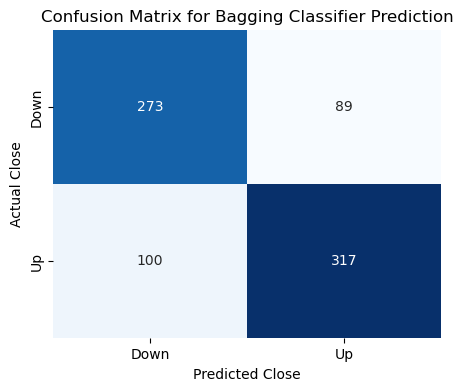

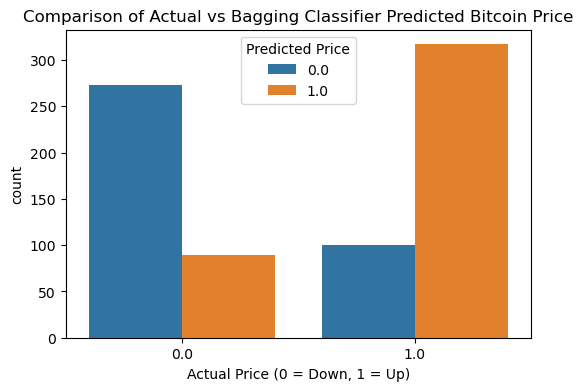

In [ ]:
#Train and test the Bagging Classifier
bag_clf.fit(bitc_eth_snp_X_train, bitc_eth_snp_y_train)
bag_pred = bag_clf.predict(bitc_eth_snp_X_test)

# Model Evaluation
# Get precision score
bg_precision_eth_snp = precision_score(bitc_eth_snp_y_test, bag_pred) 
print("Precision Score: ", bg_precision_eth_snp) 

# Get accuracy score 
bg_accuracy_eth_snp = accuracy_score(bitc_eth_snp_y_test, bag_pred) 
print("Accuracy Score: ", bg_accuracy_eth_snp)

# Get precision score
#print("Precision Score: ", precision_score(BitC_targ_test, bag_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(BitC_targ_test, bag_pred))

# Compute confusion matrix
bag_cm = confusion_matrix(bitc_eth_snp_y_test, bag_pred)

# Visualising Bagging Classifier result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(bag_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Bagging Classifier Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising Bagging Classifier result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": bitc_eth_snp_y_test,
    "Predicted": bag_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Bagging Classifier Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### Build the Random Forest Classifier for Dataset with ETH and S&P

Precision Score:  0.7651331719128329
Accuracy Score:  0.7458279845956355


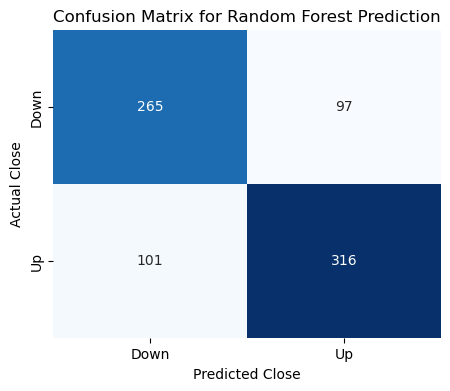

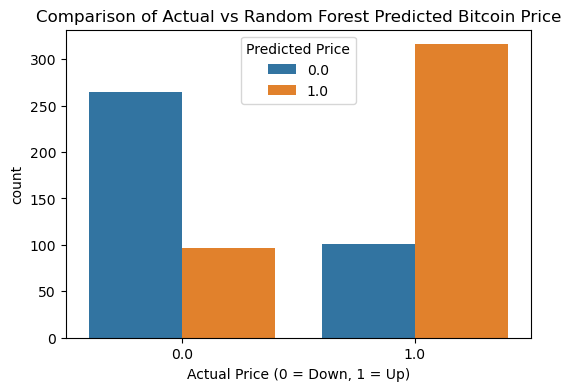

In [ ]:
## Train and test the new dataframe with the already Instantiated Random Forest Classifier

rnd_clsf.fit(bitc_eth_snp_X_train, bitc_eth_snp_y_train)
rn_fr_pred = rnd_clsf.predict(bitc_eth_snp_X_test)

# Model Evaluation
rn_precision_eth_snp = precision_score(bitc_eth_snp_y_test, rn_fr_pred) 
print("Precision Score: ", rn_precision_eth_snp) 

# Get accuracy score 
rn_accuracy_eth_snp = accuracy_score(bitc_eth_snp_y_test, rn_fr_pred) 
print("Accuracy Score: ", rn_accuracy_eth_snp)

# Compute confusion matrix
rn_fr_cm = confusion_matrix(bitc_eth_snp_y_test, rn_fr_pred)

# Visualising Random Forest result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(rn_fr_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for Random Forest Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising Random Forest result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": bitc_eth_snp_y_test,
    "Predicted": rn_fr_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs Random Forest Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

##### Build the GradientBoosting Classifier for Dataset with ETH and S&P

Precision Score:  0.7766990291262136
Accuracy Score:  0.7573812580231065


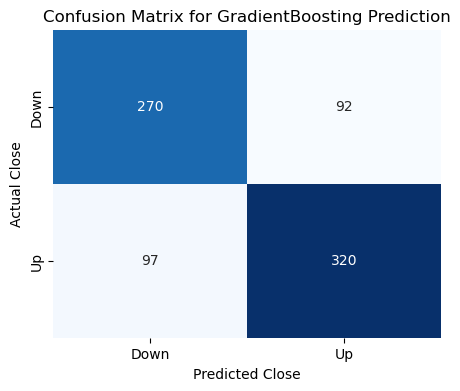

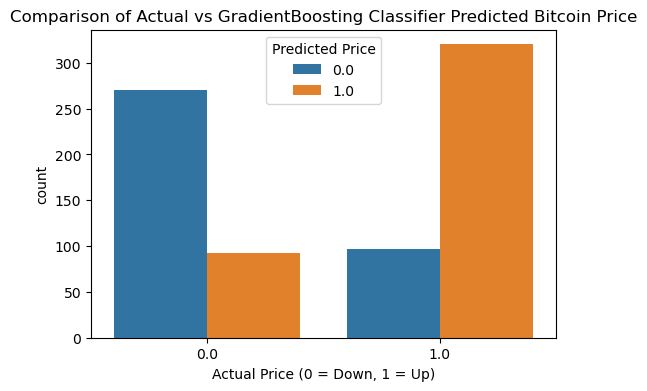

In [ ]:
# Train and test the model
gb_clf.fit(bitc_eth_snp_X_train, bitc_eth_snp_y_train)
gb_eth_snp_y_pred = gb_clf.predict(bitc_eth_snp_X_test)

# Model Evaluation
# Get precision score 
gb_precision_eth_snp = precision_score(bitc_eth_snp_y_test, gb_eth_snp_y_pred) 
print("Precision Score: ", gb_precision_eth_snp) 
# Get accuracy score 
gb_accuracy_eth_snp = accuracy_score(bitc_eth_snp_y_test, gb_eth_snp_y_pred) 
print("Accuracy Score: ", gb_accuracy_eth_snp)

# Get precision score
#print("Precision Score: ", precision_score(bitc_eth_snp_y_test, gb_eth_snp_y_pred))

# Get accuracy score
#print("Accuracy Score: ", accuracy_score(bitc_eth_snp_y_test, gb_eth_snp_y_pred))

# Get confusion matrix
gb_cm = confusion_matrix(bitc_eth_snp_y_test, gb_eth_snp_y_pred)

# Visualising GradientBoosting Classifier result using Confusion Matrix Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(gb_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
           xticklabels={"Down", "Up"}, yticklabels={"Down", "Up"})
plt.title ("Confusion Matrix for GradientBoosting Prediction")
plt.xlabel("Predicted Close")
plt.ylabel("Actual Close")
plt.show()

# Visualising GradientBoosting Classifier result using Bar Chart - Predicted vs Actual Counts
#Create DataFrame comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": bitc_eth_snp_y_test,
    "Predicted": gb_eth_snp_y_pred
})

# Count combinations of actual vs predicted classes
counts = comparison_df.value_counts().reset_index(name="count")

# Plot grouped bar chart
plt.figure(figsize=(6,4))
sns.barplot(data=counts, x="Actual", y="count", hue="Predicted")
plt.title("Comparison of Actual vs GradientBoosting Classifier Predicted Bitcoin Price")
plt.xlabel("Actual Price (0 = Down, 1 = Up)")
plt.ylabel("count")
plt.legend(title="Predicted Price")
plt.show()

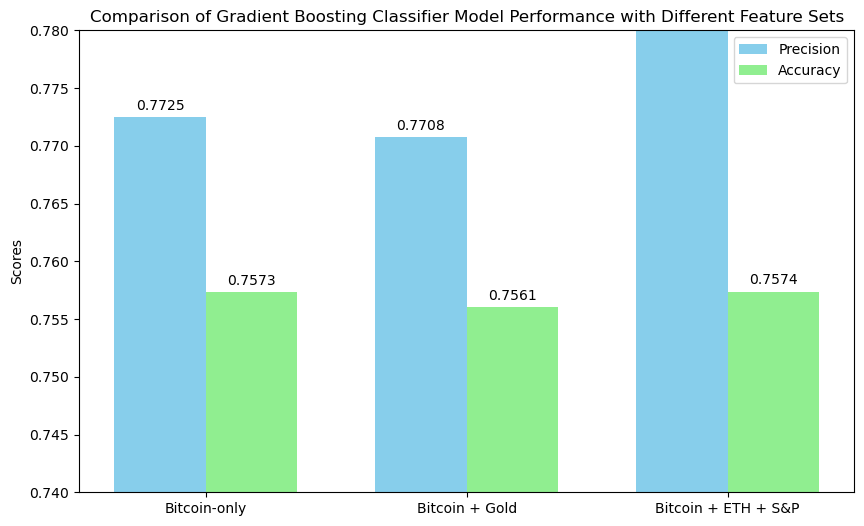

In [ ]:

# Comparison of the effect of Gold, Ethereum & S&P 500 on Bitcoin price prediction, using the best model - Bagging Classifier
models = ["Bitcoin-only", "Bitcoin + Gold", "Bitcoin + ETH + S&P"]

# Precision and Accuracy scores
precision = [bg_precision, bg_precision_gold, bg_precision_eth_snp]
accuracy = [bg_accuracy, bg_accuracy_gold, bg_accuracy_eth_snp]

# Set up bar positions
x = np.arange(len(models))
width = 0.35

# Plot
fig, ax = plt.subplots(figsize=(10,6))
rects1 = ax.bar(x - width/2, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x + width/2, accuracy, width, label='Accuracy', color='lightgreen')

# Add labels, title, legend
ax.set_ylabel('Scores')
ax.set_title('Comparison of Gradient Boosting Classifier Model Performance with Different Feature Sets')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Annotate bars with values
for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.ylim(0.74, 0.78)  # zoom in for better comparison
plt.show()

In [ ]:
Different models predicting on the bitcoin data alone

Observation: Gradient Boosting gives the highest precision, improving about 9.2% over Logistic Regression. Random Forest and Bagging are very close, improving roughly 8.6–8.7%.

Observation: Accuracy improves modestly across ensemble methods compared to Logistic Regression, with Random Forest giving the highest boost (~1.35%). Precision gains are more significant than accuracy gains, suggesting the ensembles are better at correctly predicting the “up” class without much compromise in overall correctness.

Interpretation: Adding Ethereum and S&P slightly improved the model performance. Ethereum, trading 24/7 like Bitcoin, contributes useful predictive information, while S&P adds some market trend context. The improvement is modest but measurable, particularly in precision.
Summary

Precision benefits more than accuracy when moving from Logistic Regression to ensemble models.

Gradient Boosting slightly outperforms Bagging and Random Forest in precision, while Random Forest has a slight edge in accuracy.

Using ensemble methods is clearly worthwhile if the goal is better identification of upward price trends, since precision improves by almost 9% relative to Logistic Regression.


Different dataset with Gradient Boosting as predictive model
Conclusion:

Gold Close does not help the model.

Ethereum Close provides the biggest marginal gain due to its trading calendar alignment with Bitcoin.

S&P Close contributes a tiny additional improvement.

SyntaxError: invalid decimal literal (3580345086.py, line 1)